# Sampling the score

`CoxDeviance.sample_score()` draws the score of the Cox model at a linear
predictor, by one of four methods, and `CoxDeviance.wild_score()` gives the
wild draw for multipliers of your choosing. This notebook compares the
methods on data with heavy ties. For the basics of `CoxDeviance`, see
`using_coxdev.md`. The R package has the same vignette.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import gaussian_kde, norm
from coxdev import CoxDeviance
from glmnet.cox import CoxFamily, CoxNetIRLS
from glmnet.glmnet import GLMNetControl

## A survival response

Survival times on a coarse grid, so that there are many ties, with delayed
entry and censoring.

In [2]:
rng = np.random.default_rng(1)
n, p = 500, 3
X = rng.standard_normal((n, p))
beta = np.array([0.5, -0.5, 0.25])
T = rng.exponential(1 / np.exp(X @ beta))
C = rng.exponential(2, n)
stop = np.ceil(np.minimum(T, C) * 4) / 4
status = (T <= C).astype(int)
start = np.floor(rng.uniform(0, 0.5, n) * stop * 8) / 8

cox = CoxDeviance(event=stop, status=status, start=start, tie_breaking='efron')

We sample at the estimate of the coefficients, from `CoxNetIRLS` in
`glmstar`, the Python glmnet, with no penalty:

In [3]:
y = pd.DataFrame({'start': start, 'stop': stop, 'status': status})
coxnet = CoxNetIRLS(family=CoxFamily(tie_breaking='efron', event_id='stop',
                                     status_id='status', start_id='start'),
                    lambda_values=np.array([0.]),
                    control=GLMNetControl(thresh=1e-14, epsnr=1e-12))
fit = coxnet.fit(X, y)
b = fit.coefs_[0]
b

array([ 0.45071779, -0.40934599,  0.24829703])

## The methods

Each draw `r` has one entry per observation, and `X.T @ r` is a draw of the
score of the coefficients. We draw at the estimate `b`, by four methods:

- `'multinomial'`: the failures at each event time drawn with replacement,
  with probabilities proportional to `exp(eta)`. This is the sampling model
  of Breslow's likelihood, so the covariance is the Breslow information.
- `'fisher'`: the set of failures at each event time drawn from Fisher's
  noncentral hypergeometric distribution. This is the sampling model of the
  exact partial likelihood, whose information is smaller than Breslow's when
  ties are heavy.
- `'bernoulli'`: each subject at risk fails independently, with
  probability `min(1, d p)`, where `d` is the number of failures at the
  event time and `p` the subject's share of the risk. Its mean is zero only
  while `d p < 1`: under heavy ties the cap binds, and the draws are biased.
- `'wild'`: the score residuals times independent normals. Its covariance is
  the sandwich, which does not rely on the model being right.

In [4]:
eta_hat = X @ b
methods = ['multinomial', 'fisher', 'bernoulli', 'wild']
draws = {m: X.T @ cox.sample_score(eta_hat, method=m, n_draws=4000, seed=1) for m in methods}

Here are the means of the draws, in standard deviations, and their
variances relative to the Breslow information:

In [5]:
breslow = CoxDeviance(event=stop, status=status, start=start, tie_breaking='breslow')
info_breslow = X.T @ (breslow.information(eta_hat) @ X)
sd = np.sqrt(np.diag(info_breslow))
table = pd.DataFrame({m: np.r_[d.mean(1) / sd, np.diag(np.cov(d)) / np.diag(info_breslow)]
                      for m, d in draws.items()},
                     index=[f'mean x{j}' for j in (1, 2, 3)] +
                           [f'variance x{j}' for j in (1, 2, 3)]).T
table.round(2)

,mean x1,mean x2,mean x3,variance x1,variance x2,variance x3
multinomial,0.02,0.01,0.00,1.00,1.00,1.01
fisher,-0.01,-0.01,0.01,0.70,0.72,0.68
bernoulli,-0.11,0.11,-0.14,0.63,0.67,0.63
wild,-0.00,-0.01,0.01,0.69,0.73,0.67


The multinomial draws have the Breslow information as covariance, and the
Fisher draws a smaller one, the information of the exact likelihood. The
Bernoulli draws are biased: at these ties, `d p` often exceeds 1, so the
cap `min(1, d p)` gives too few failures to the subjects most at risk.

The wild draws estimate the sandwich, `U.T @ U` for the score residuals `U`
of the design, the middle of the robust variance (R's `coxph(robust = TRUE)`):

In [6]:
U = cox.score_residuals(eta_hat, X)
pd.DataFrame({'wild': np.diag(np.cov(draws['wild'])), 'sandwich': np.diag(U.T @ U)},
             index=['x1', 'x2', 'x3']).T

,x1,x2,x3
wild,190.900213,192.716815,207.247227
sandwich,196.736414,193.938035,210.671545


The distributions of the first coefficient's score:

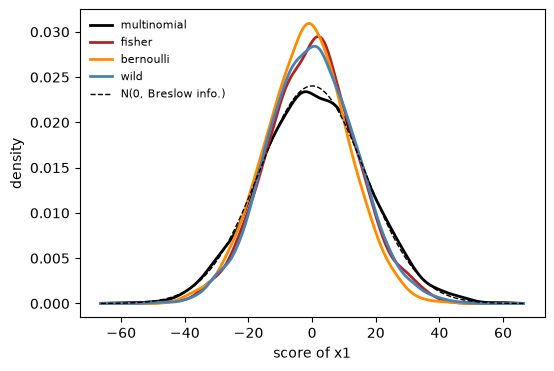

In [7]:
fig, ax = plt.subplots(figsize=(6, 4))
grid = np.linspace(-4, 4, 400) * sd[0]
colors = {'multinomial': 'black', 'fisher': 'firebrick', 'bernoulli': 'darkorange',
          'wild': 'steelblue'}
for m in methods:
    ax.plot(grid, gaussian_kde(draws[m][0])(grid), color=colors[m], lw=2, label=m)
ax.plot(grid, norm.pdf(grid, scale=sd[0]), 'k--', lw=1, label='N(0, Breslow info.)')
ax.set_xlabel('score of x1')
ax.set_ylabel('density')
ax.legend(frameon=False, fontsize=8, loc='upper left');

## Choosing the multipliers

`wild_score()` gives the wild draw for multipliers you choose: the sum over
observations of the multiplier times the score residual, `G @ U`. With
multipliers all one it is the score itself. Other multipliers give other
wild bootstraps, here Rademacher signs in place of normals:

In [8]:
print(np.allclose(cox.wild_score(eta_hat, np.ones(n)), -cox(eta_hat).gradient / 2))
G = rng.choice([-1., 1.], size=(4000, n))
rademacher = np.array([X.T @ cox.wild_score(eta_hat, g) for g in G]).T
pd.DataFrame({'rademacher': np.diag(np.cov(rademacher)), 'sandwich': np.diag(U.T @ U)},
             index=['x1', 'x2', 'x3']).T

True


,x1,x2,x3
rademacher,189.081815,201.067896,222.918216
sandwich,196.736414,193.938035,210.671545


## Reproducibility

The same seed gives the same draws on every platform, and from the R
package. With `seed=None`, a fresh seed is drawn from numpy's entropy.

In [9]:
np.array_equal(cox.sample_score(eta_hat, method='fisher', seed=7),
               cox.sample_score(eta_hat, method='fisher', seed=7))

True